# SmartFish - Hybrid Fish Disease Classifier Training

Trains the EfficientNet-B4 + ViT-B/16 hybrid classifier on GPU.

**Before running:**
1. `Runtime > Change runtime type > T4 GPU`
2. Upload the whole `SmartFish` project folder to your Google Drive, at `MyDrive/SmartFish` (must include the `src/` folder).
3. Get a Kaggle API token: kaggle.com -> Settings -> Create New Token -> downloads `kaggle.json`. You'll upload it in the cell below.

In [ ]:
!nvidia-smi

Wed Aug 19 05:02:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/SmartFish
!ls

/content/drive/MyDrive/SmartFish
backend  frontend  notebooks  README.md  requirements.txt  src	venv


In [ ]:
# Colab already ships torch/torchvision/numpy/pandas/matplotlib/scikit-learn with CUDA wired up --
# only install what's missing, to avoid a slow/incompatible torch reinstall.
!pip install -q timm albumentations kagglehub opencv-python-headless seaborn

In [ ]:
# Upload the kaggle.json you downloaded from kaggle.com/settings
import os
from google.colab import files

uploaded = files.upload()  # select kaggle.json
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
import sys
sys.path.append('src')

In [11]:
%%writefile src/config.py
"""
Central config for the SmartFish hybrid disease classifier.

Dataset note
------------
The poster's target taxonomy has 11 classes (Bacterial/Fungal/Parasitic/Viral,
Fin Rot, Tail Rot, Gill Disease, Ich, Ulcer Disease, Dropsy, Healthy). No single
public dataset with clean labels covers all 11 with enough images per class.

This project merges two Kaggle datasets:

  "Freshwater Fish Disease Aquaculture in South Asia" (subirbiswas19)
    Bacterial diseases - Aeromoniasis, Bacterial gill disease,
    Bacterial Red disease, Fungal diseases Saprolegniasis, Healthy Fish,
    Parasitic diseases, Viral diseases White tail disease
    (~350 images/class)

  "Fresh Water Fish Disease Dataset" (utpolkantidas)
    Argulus, Bacterial Gill Rot, Broken Antennae and Rostrum, EUS, Healthy
    Fish, Red Spot, Tail and Fin Rot (6-31 images/class - small)

Red Spot / Bacterial Gill Rot / Argulus / Healthy Fish are folded into the
matching class above (bulks up volume, same underlying condition). EUS and
Tail and Fin Rot become two new classes (Ulcer_Disease, Tail_And_Fin_Rot) --
real disease categories from the poster's 11, but thin (9-23 images), so
expect noticeably weaker accuracy on those two specifically. Broken Antennae
and Rostrum is physical injury, not a disease in the poster's taxonomy, and
is left unmatched/skipped on purpose.

That gets to 9 of the poster's 11 classes. Fin Rot/Tail Rot as *separate*
classes and Dropsy still aren't represented in usable volume in public data
as of writing -- extend CLASS_NAMES/CLASS_KEYWORDS below and re-run
dataset_prep.py if you add more images under dataset/raw/<class_name>/.
"""

from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parent.parent

RAW_DATA_DIR = PROJECT_ROOT / "dataset" / "raw"
SPLIT_DATA_DIR = PROJECT_ROOT / "dataset" / "split"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

CLASS_NAMES = [
    "Bacterial_Aeromoniasis",
    "Bacterial_Gill_Disease",
    "Bacterial_Red_Disease",
    "Fungal_Saprolegniasis",
    "Parasitic_Disease",
    "Viral_White_Tail_Disease",
    "Ulcer_Disease",
    "Tail_And_Fin_Rot",
    "Healthy",
]
NUM_CLASSES = len(CLASS_NAMES)

# Lowercase keyword fragments used to auto-map the Kaggle downloads' actual
# folder names (which vary in punctuation/casing, and come from two source
# datasets) onto CLASS_NAMES above.
CLASS_KEYWORDS = {
    "Bacterial_Aeromoniasis": ["aeromon"],
    "Bacterial_Gill_Disease": ["gill"],
    "Bacterial_Red_Disease": ["red"],
    "Fungal_Saprolegniasis": ["fungal", "saprolegni"],
    "Parasitic_Disease": ["parasit", "argulus"],
    "Viral_White_Tail_Disease": ["viral", "white tail", "white_tail", "whitetail"],
    "Ulcer_Disease": ["eus", "epizootic ulcerative", "ulcer"],
    "Tail_And_Fin_Rot": ["tail and fin", "tail_and_fin", "tail rot", "fin rot"],
    "Healthy": ["healthy"],
}

TREATMENT_RECOMMENDATIONS = {
    "Bacterial_Aeromoniasis": {
        "severity_hint": "High",
        "treatment": "Isolate affected fish; antibiotic-medicated feed or bath "
        "(vet-prescribed, e.g. oxytetracycline) per local aquaculture guidance.",
        "prevention": "Improve water quality, reduce stocking density, avoid handling stress.",
    },
    "Bacterial_Gill_Disease": {
        "severity_hint": "High",
        "treatment": "Improve aeration and water exchange; salt bath or vet-approved "
        "antibacterial treatment.",
        "prevention": "Maintain low ammonia/nitrite, avoid overcrowding, quarantine new stock.",
    },
    "Bacterial_Red_Disease": {
        "severity_hint": "High",
        "treatment": "Vet-prescribed antibiotic treatment; isolate affected fish immediately.",
        "prevention": "Strict water quality control, disinfect equipment between ponds/tanks.",
    },
    "Fungal_Saprolegniasis": {
        "severity_hint": "Moderate",
        "treatment": "Salt bath or antifungal treatment (e.g. formalin/malachite green "
        "alternatives per local regulation); remove dead tissue.",
        "prevention": "Avoid skin injury, keep water clean and at stable temperature.",
    },
    "Parasitic_Disease": {
        "severity_hint": "Moderate",
        "treatment": "Anti-parasitic bath treatment; identify parasite type for targeted dosing.",
        "prevention": "Quarantine new fish, regular water testing, avoid overfeeding.",
    },
    "Viral_White_Tail_Disease": {
        "severity_hint": "Critical",
        "treatment": "No specific cure; supportive care, isolate and remove affected fish "
        "to limit spread, disinfect equipment.",
        "prevention": "Source disease-free broodstock, avoid stress, maintain biosecurity.",
    },
    "Ulcer_Disease": {
        "severity_hint": "Critical",
        "treatment": "No specific cure for EUS; supportive care, isolate affected fish, "
        "improve water quality immediately, consult a fish health specialist for outbreak management.",
        "prevention": "Avoid cold/low-pH stress periods, maintain good water quality, "
        "avoid overcrowding, quarantine new stock.",
    },
    "Tail_And_Fin_Rot": {
        "severity_hint": "Moderate",
        "treatment": "Improve water quality immediately; salt bath or vet-approved "
        "antibacterial/antifungal treatment; trim badly damaged tissue only if vet-advised.",
        "prevention": "Avoid overcrowding and fin nipping/injury, maintain clean water, "
        "avoid sudden temperature swings.",
    },
    "Healthy": {
        "severity_hint": "None",
        "treatment": "No treatment needed.",
        "prevention": "Maintain current water quality and feeding regimen.",
    },
}

# ---- data ----
IMG_SIZE = 224
TRAIN_SPLIT = 0.70
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
SEED = 42

# ---- training ----
BATCH_SIZE = 32
EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.3

# ---- backbones (timm model names) ----
CNN_BACKBONE = "efficientnet_b4"
VIT_BACKBONE = "vit_base_patch16_224"
FUSION_DIM = 512

Overwriting src/config.py


In [12]:
%%writefile src/dataset_prep.py
"""
Download the Kaggle fish-disease datasets, sort them into dataset/raw/<class>/,
then make a stratified 70/15/15 train/val/test split under dataset/split/.

Run once before training (safe to re-run after editing CLASS_KEYWORDS -- it
merges into existing dataset/raw/ rather than wiping it):
    python src/dataset_prep.py

Requires a Kaggle account + API token (https://www.kaggle.com/settings ->
API section -> "Create Legacy API Key" -> save kaggle.json to
~/.kaggle/kaggle.json, or set the KAGGLE_USERNAME / KAGGLE_KEY environment
variables). kagglehub picks these up automatically.
"""

from __future__ import annotations

import random
import shutil
from pathlib import Path

import kagglehub

from config import CLASS_KEYWORDS, CLASS_NAMES, RAW_DATA_DIR, SEED, SPLIT_DATA_DIR, \
    TEST_SPLIT, TRAIN_SPLIT, VAL_SPLIT

KAGGLE_DATASETS = [
    "subirbiswas19/freshwater-fish-disease-aquaculture-in-south-asia",
    "utpolkantidas/fresh-water-fish-disease-dataset",
]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def match_class(folder_name: str) -> str | None:
    name = folder_name.lower()
    for class_name, keywords in CLASS_KEYWORDS.items():
        if any(kw in name for kw in keywords):
            return class_name
    return None


def collect_source_images(download_root: Path, buckets: dict[str, list[Path]],
                           unmatched_dirs: set[str]) -> None:
    """Walk one downloaded dataset and bucket its image files by matched class."""
    for path in download_root.rglob("*"):
        if path.suffix.lower() not in IMAGE_EXTS or not path.is_file():
            continue
        folder_name = path.parent.name
        matched = match_class(folder_name)
        if matched:
            buckets[matched].append(path)
        else:
            unmatched_dirs.add(folder_name)


def copy_into_raw(buckets: dict[str, list[Path]]) -> None:
    RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
    for class_name, files in buckets.items():
        class_dir = RAW_DATA_DIR / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        for i, src in enumerate(files):
            dst = class_dir / f"{class_name}_{i:04d}{src.suffix.lower()}"
            if not dst.exists():
                shutil.copyfile(src, dst)
        print(f"  {class_name:30s} {len(files):4d} images")


def stratified_split() -> None:
    random.seed(SEED)
    for split in ("train", "val", "test"):
        for class_name in CLASS_NAMES:
            (SPLIT_DATA_DIR / split / class_name).mkdir(parents=True, exist_ok=True)

    print("\nSplitting 70/15/15 (train/val/test):")
    for class_name in CLASS_NAMES:
        class_dir = RAW_DATA_DIR / class_name
        files = sorted(class_dir.glob("*"))
        random.shuffle(files)

        n = len(files)
        n_train = int(n * TRAIN_SPLIT)
        n_val = int(n * VAL_SPLIT)
        splits = {
            "train": files[:n_train],
            "val": files[n_train:n_train + n_val],
            "test": files[n_train + n_val:],
        }
        for split, split_files in splits.items():
            for src in split_files:
                dst = SPLIT_DATA_DIR / split / class_name / src.name
                shutil.copyfile(src, dst)
        print(f"  {class_name:30s} train={len(splits['train']):4d} "
              f"val={len(splits['val']):4d} test={len(splits['test']):4d}")


def main() -> None:
    buckets: dict[str, list[Path]] = {c: [] for c in CLASS_NAMES}
    unmatched_dirs: set[str] = set()

    for dataset_slug in KAGGLE_DATASETS:
        print(f"Downloading '{dataset_slug}' from Kaggle (cached after first run)...")
        download_root = Path(kagglehub.dataset_download(dataset_slug))
        print(f"Downloaded to: {download_root}")
        collect_source_images(download_root, buckets, unmatched_dirs)

    if unmatched_dirs:
        print(f"\n[warn] {len(unmatched_dirs)} folder(s) didn't match any class "
              f"and were skipped: {sorted(unmatched_dirs)}")
        print("       Extend CLASS_KEYWORDS in src/config.py if one of these "
              "should map to a class.")

    print("\nSorting images into dataset/raw/<class>/:")
    empty = [c for c, files in buckets.items() if not files]
    if empty:
        print(f"[warn] no images found for: {empty} "
              "(check CLASS_KEYWORDS match the dataset's folder names)")
    copy_into_raw(buckets)

    stratified_split()
    print(f"\nDone. Split dataset ready at: {SPLIT_DATA_DIR}")


if __name__ == "__main__":
    main()

Overwriting src/dataset_prep.py


## 1. Download + prepare the dataset

Downloads the Kaggle "Freshwater Fish Disease Aquaculture in South Asia" dataset, sorts it into `dataset/raw/<class>/`, then makes a stratified 70/15/15 split under `dataset/split/`.

In [13]:
!python src/dataset_prep.py

Using Colab cache for faster access to the 'freshwater-fish-disease-aquaculture-in-south-asia' dataset.
Downloaded to: /kaggle/input/freshwater-fish-disease-aquaculture-in-south-asia
100% 3.86M/3.86M [00:00<00:00, 159MB/s]
Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/utpolkantidas/fresh-water-fish-disease-dataset/versions/1

[warn] 1 folder(s) didn't match any class and were skipped: ['Broken antennae and rostrum']
       Extend CLASS_KEYWORDS in src/config.py if one of these should map to a class.

Sorting images into dataset/raw/<class>/:
  Bacterial_Aeromoniasis          350 images
  Bacterial_Gill_Disease          356 images
  Bacterial_Red_Disease           381 images
  Fungal_Saprolegniasis           350 images
  Parasitic_Disease               373 images
  Viral_White_Tail_Disease        344 images
  Ulcer_Disease                    26 images
  Tail_And_Fin_Rot                  9 images
  Healthy                         381 images

Splitting 70/15/15 (train

## 2. Train

AdamW + ReduceLROnPlateau, batch 32, up to 100 epochs with early stopping (patience 10). CutMix applied to ~30% of training batches. Best checkpoint (by val loss) is saved to `models/best_model.pt`.

In [14]:
!python src/train.py --epochs 10

Device: cuda
Classes (9): ['Bacterial_Aeromoniasis', 'Bacterial_Gill_Disease', 'Bacterial_Red_Disease', 'Fungal_Saprolegniasis', 'Parasitic_Disease', 'Viral_White_Tail_Disease', 'Ulcer_Disease', 'Tail_And_Fin_Rot', 'Healthy']
Train batches: 80 | Val batches: 24

model.safetensors: downloading bytes:   1% 493k/77.9M [00:00<02:15, 572kB/s]
model.safetensors: downloading bytes:  18% 14.2M/77.9M [00:00<00:03, 19.9MB/s, 48.6kB/s  ]
model.safetensors: downloading bytes:  71% 55.5M/77.9M [00:01<00:00, 43.2MB/s, 4.83MB/s  ]
model.safetensors: reconstructing file:  20% 15.6M/77.9M [00:01<00:06, 10.2MB/s, 1.39MB/s  ]
model.safetensors: downloading bytes:  88% 68.3M/77.9M [00:01<00:00, 42.9MB/s, 5.60MB/s  ]
model.safetensors: downloading bytes: 100% 73.8M/73.8M [00:02<00:00, 34.1MB/s, 6.65MB/s  ]
model.safetensors: reconstructing file: 100% 77.9M/77.9M [00:02<00:00, 36.0MB/s, 7.30MB/s  ]

model.safetensors: downloading bytes:   0% 0.00/346M [00:00<?, ?B/s]
model.safetensors: downloading bytes:   

## 3. Evaluate on the held-out test set

In [15]:
!python src/evaluate.py

Loaded checkpoint from epoch 9 (val_loss=0.0897, val_acc=0.9762)
Test samples: 780
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

{
  "accuracy": 0.9717948717948718,
  "precision_macro": 0.7568944559951849,
  "recall_macro": 0.7625416225143993,
  "f1_macro": 0.7595732392032442,
  "specificity_macro": 0.9963271103996713,
  "roc_auc_macro": 0.968834763735042,
  "specificity_per_class": {
    "Bacterial_Aeromoniasis": 1.0,
    "Bacterial_Gill_Disease": 0.9954819277108434,
    "Bacterial_Red_Disease": 0.990990990990991,
    "Fungal_Saprolegniasis": 0.9970282317979198,
    "Parasitic_Disease": 0.9985052316890882,
    "Viral_White_Tail_Disease": 0.9970588235294118,
    "Ulcer_Disease": 1.0,
    "Tail_And_Fin_Rot": 1.0,
    "Healthy": 0.9878787878787879
  },
  "n_test_samples": 780
}


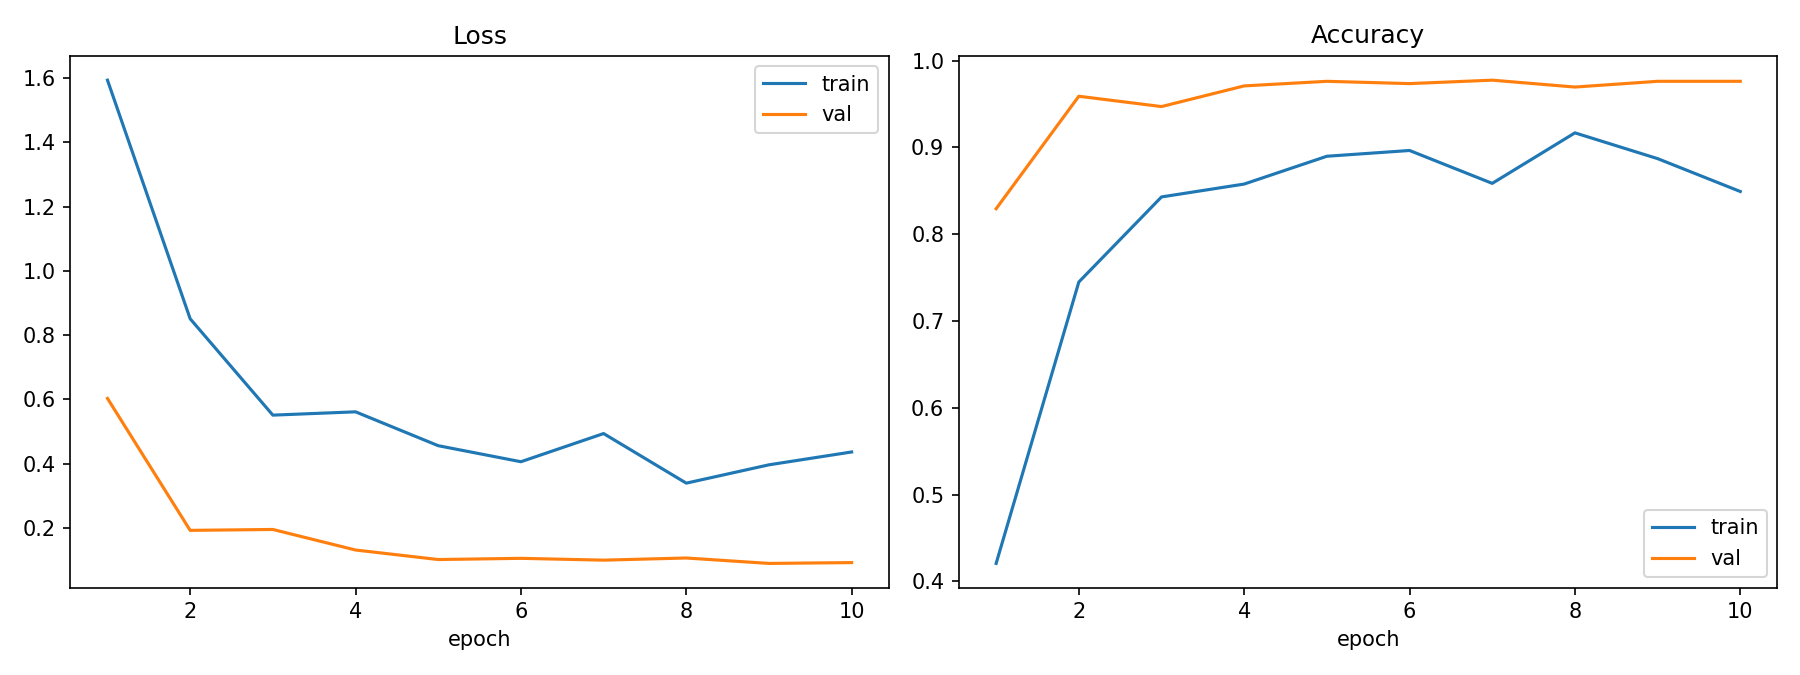

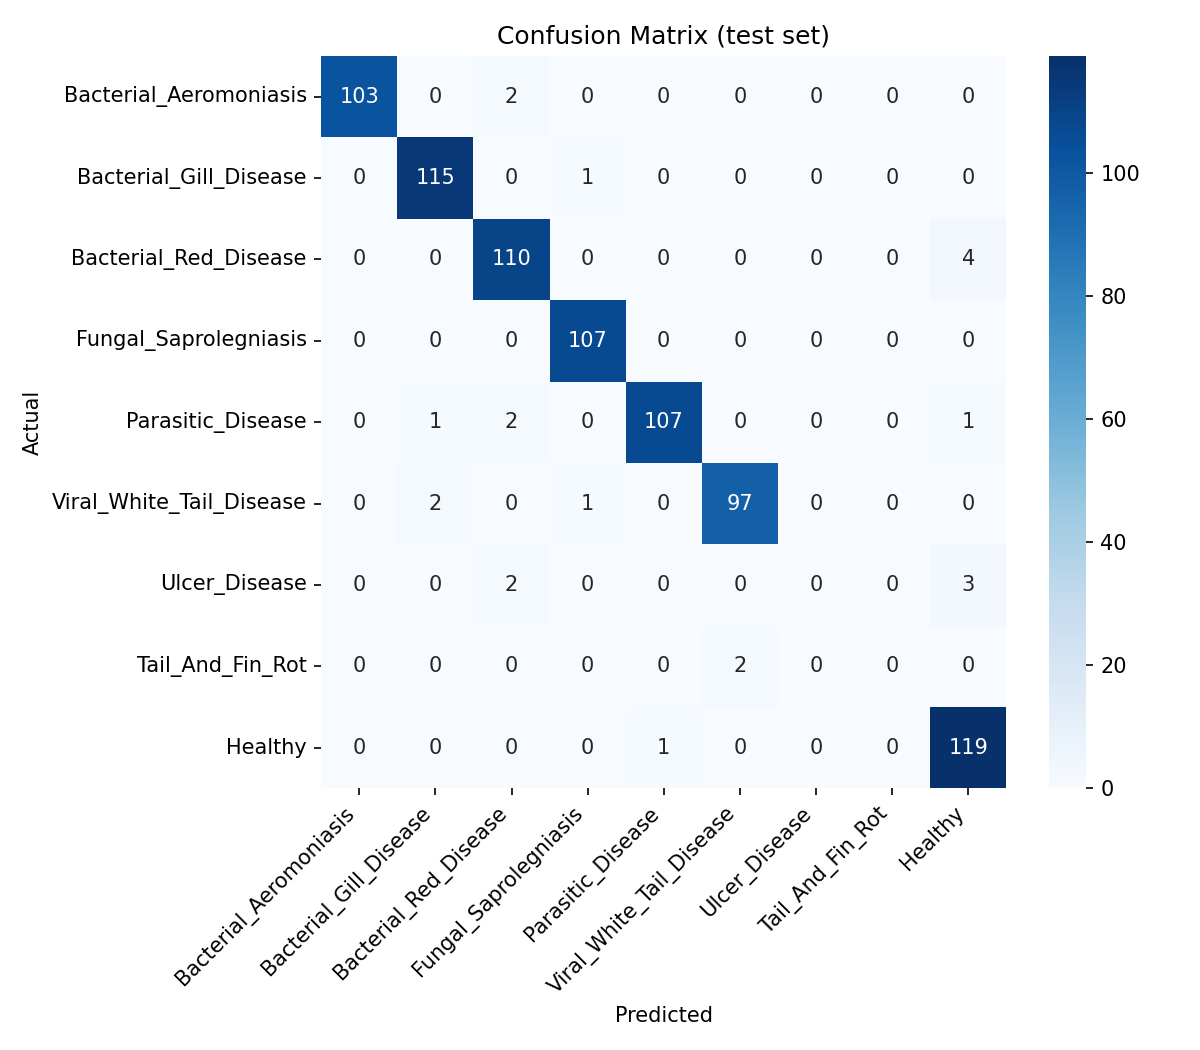

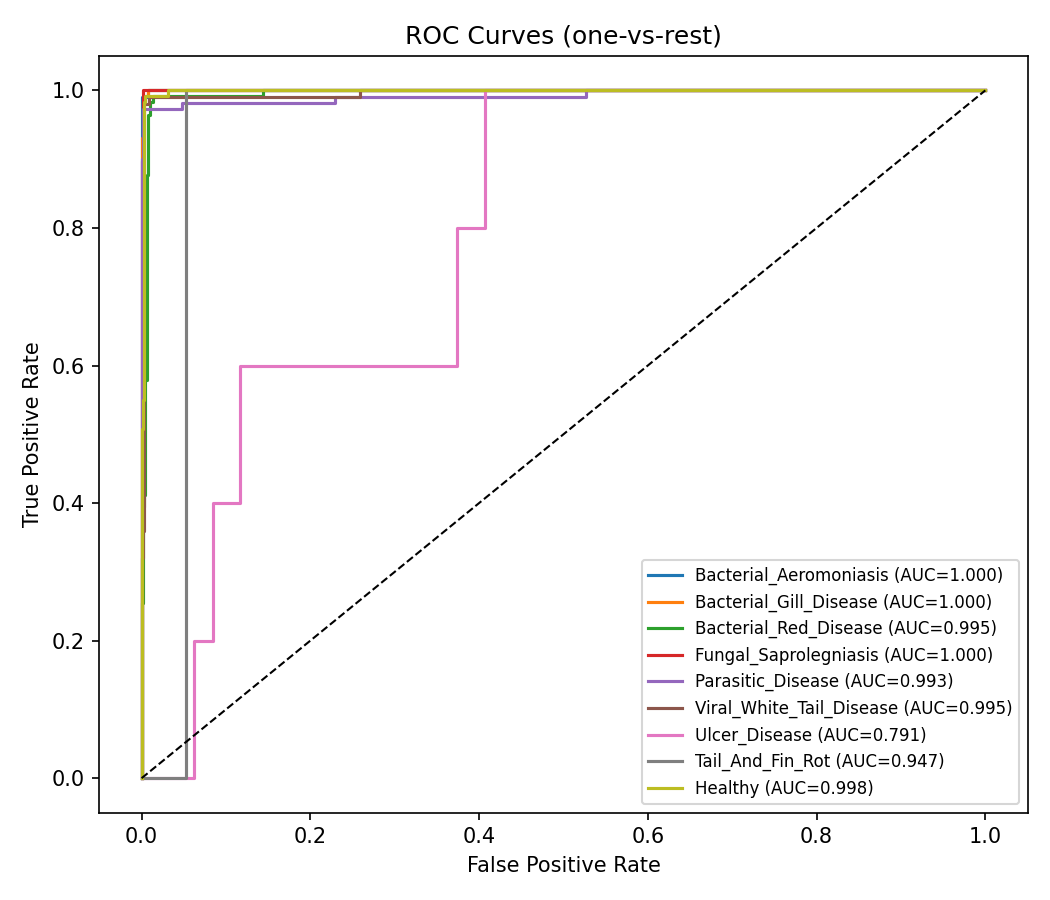

In [16]:
import json
from IPython.display import Image, display

with open('results/metrics.json') as f:
    print(json.dumps(json.load(f), indent=2))

display(Image('results/training_curves.png'))
display(Image('results/confusion_matrix.png'))
display(Image('results/roc_curves.png'))

## 4. Get the trained model back to your machine

`models/best_model.pt` is already saved inside your mounted Google Drive (`MyDrive/SmartFish/models/`), so it'll show up there automatically. The cell below also offers a direct browser download -- copy it into your local `SmartFish/models/` folder so `backend/` can load it.

In [17]:
from google.colab import files
files.download('models/best_model.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>